# EDA con Visualizaciones — Histogramas y Boxplots con Seaborn

En esta clase vamos a aprender a graficar dos de las visualizaciones más importantes para el análisis exploratorio de datos:

- **Histogramas**: muestran la distribución de una variable continua.
- **Boxplots**: resumen visualmente las medidas de posición y dispersión (mediana, cuartiles, outliers).

Usaremos **Seaborn** como librería principal. Seaborn está construida sobre Matplotlib y ofrece una sintaxis más simple y gráficos más prolijos por defecto. Para los ajustes de tamaño, títulos y subplots, igual vamos a apoyarnos en Matplotlib — eso es lo habitual en la práctica.

---

### Dataset: `tips`

Vamos a trabajar con el dataset `tips`, que viene incorporado en Seaborn. Registra información sobre propinas en un restaurante:

| Columna | Descripción |
|---|---|
| `total_bill` | Monto total de la cuenta (en dólares) |
| `tip` | Monto de la propina |
| `sex` | Género del cliente |
| `smoker` | Si fuma o no |
| `day` | Día de la semana |
| `time` | Almuerzo o cena |
| `size` | Cantidad de personas en la mesa |

## 1. Importaciones y carga de datos

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Cargamos el dataset tips directamente desde Seaborn
tips = sns.load_dataset("tips")

tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [3]:
# Resumen estadístico rápido
# Antes de graficar, siempre es buena práctica explorar los datos
# tips.describe()
tips.describe(include="category")

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


---

## 2. Histograma con Seaborn

Un histograma divide el rango de valores de una variable en intervalos (*bins*) y cuenta cuántas observaciones caen en cada uno. Es la forma más directa de ver la **forma de la distribución**.

La función principal es `sns.histplot()`.

```python
sns.histplot(data=df, x="columna")
```

Parámetros más útiles:

| Parámetro | Qué hace |
|---|---|
| `data` | El DataFrame |
| `x` | La columna a graficar |
| `bins` | Cantidad de barras |
| `kde` | Superpone una curva de densidad (KDE) |
| `color` | Color de las barras |
| `hue` | Separa por categoría (ej: género) |

### 2.1 Histograma simple — `total_bill`

In [4]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [5]:
tips["day"].value_counts()

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

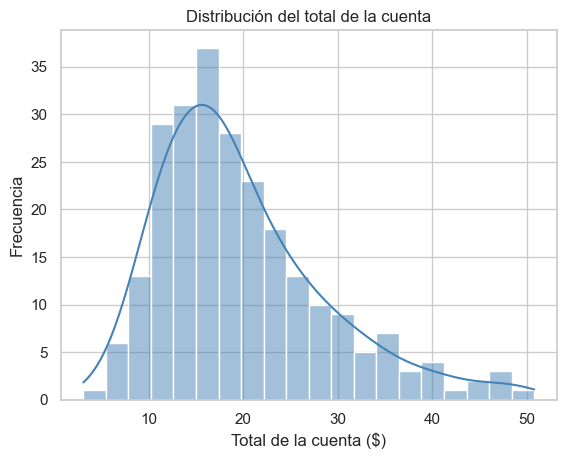

In [6]:
# Aplicamos un estilo global
sns.set_theme(style="whitegrid")

# Invocamos el método para hacer el plot histograma
sns.histplot(
    data=tips,
    x="total_bill",
    bins=20,
    color="steelblue",
    kde=True)

# Configuramos el título del plot
plt.title("Distribución del total de la cuenta")

# Etiquetas de los ejes x e y
plt.xlabel("Total de la cuenta ($)")
plt.ylabel("Frecuencia")

# Generamos el gráfico
plt.show()

**Para explorar:**
- Cambiá el valor de `bins` (probá 5, 10, 30). ¿Qué pasa con la forma del gráfico?
- Probá `kde=False` para ver el histograma sin la curva.
- ¿La distribución es simétrica o tiene sesgo? ¿Hacia qué lado?

### 2.2 Histograma con `hue` — comparando grupos

El parámetro `hue` permite separar la distribución por una variable categórica, en una sola llamada.

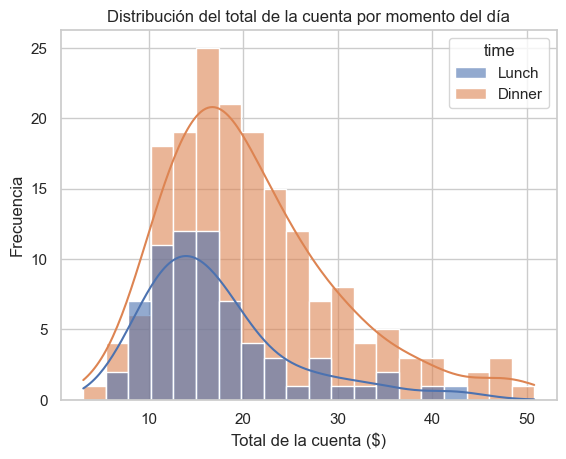

In [7]:
sns.histplot(
    data=tips,
    x="total_bill",
    hue="time",       # Separa por Lunch / Dinner
    bins=20,
    kde=True,
    alpha=0.6         # Transparencia para que se vean las barras superpuestas
)

plt.title("Distribución del total de la cuenta por momento del día")
plt.xlabel("Total de la cuenta ($)")
plt.ylabel("Frecuencia")
plt.show()

**Para explorar:**
- Cambiá `hue` por `"sex"` o `"smoker"`. ¿Cambian mucho las distribuciones?
- ¿Qué momento del día tiende a tener cuentas más altas?

---

## 3. Boxplot con Seaborn

El boxplot (diagrama de caja) es ideal para ver **medidas de posición y dispersión** de un vistazo:

```
  ┌─────────────────┐
  │   Q1  Med  Q3   │  ← La caja va de Q1 a Q3 (IQR)
  └─────────────────┘
  |                 |   ← Bigotes: hasta 1.5 × IQR
  ●                 ●   ← Puntos fuera: outliers
```

| Elemento | Qué representa |
|---|---|
| Línea del medio | Mediana (Q2) |
| Caja | Rango intercuartílico (Q1 a Q3) |
| Bigotes | Valores dentro de 1.5 × IQR |
| Puntos sueltos | Outliers |

La función es `sns.boxplot()`.

```python
sns.boxplot(data=df, x="columna")
```

### 3.1 Boxplot simple — `total_bill`

C:\Users\JPy\AppData\Local\Temp\ipykernel_12072\46887297.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


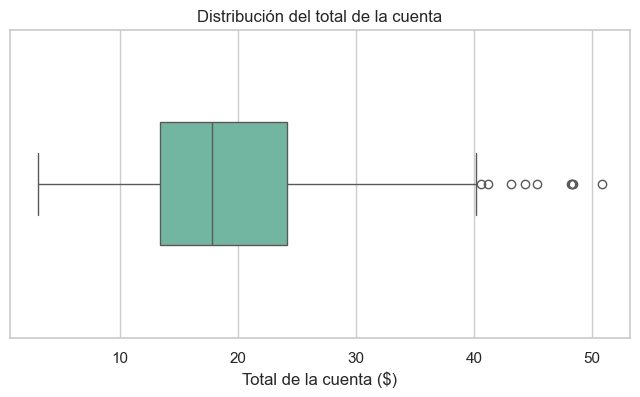

In [8]:
# Aplicamos un estilo global
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4))
# Invocamos el método para hacer el plot boxplor
sns.boxplot(
    data=tips,
    x="total_bill",
    palette="Set2",
    width=0.4
    )

# Configuramos el título del plot
plt.title("Distribución del total de la cuenta")

# Etiquetas de los ejes x e y
plt.xlabel("Total de la cuenta ($)")

# Generamos el plot
plt.show()

**Para explorar:**
- ¿Hay outliers? ¿Son muchos o pocos?
- ¿Dónde está la mediana dentro de la caja? ¿Está centrada?
- ¿Qué dice eso sobre la simetría de la distribución?

### 3.2 Boxplot con `x` categórico — comparando grupos

Cuando pasamos una variable categórica en `x` y la continua en `y`, Seaborn genera un boxplot por categoría automáticamente.

C:\Users\JPy\AppData\Local\Temp\ipykernel_12072\3419013109.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


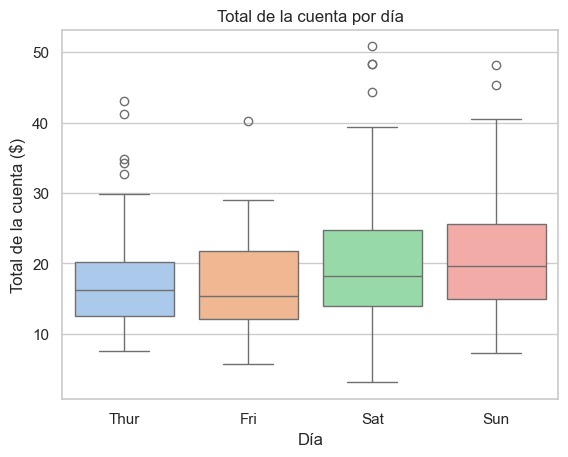

In [9]:
sns.boxplot(
    data=tips,
    y="total_bill", # Variable numérica en el eje Y
    x ="day", # Variable categórica en el eje X
    palette="pastel",  # Paleta de colores suave
)

plt.title("Total de la cuenta por día")
plt.xlabel("Día")
plt.ylabel("Total de la cuenta ($)")
plt.show()

**Para explorar:**
- ¿Qué día tiene las cuentas más altas en promedio?
- ¿Qué día tiene mayor dispersión?
- Agregá `hue="sex"` para ver diferencias por género dentro de cada día.

## 4. Evaluar normalidad: Test de Shapiro-wilk
El test de Shapiro–Wilk test permite evaluar si una muestra sigue una distribución normal. La hipótesis nula (H₀) asume que los datos provienen de una distribución normal. Si el p-value es mayor a 0.05, no se rechaza la normalidad; si es menor o igual a 0.05, existen evidencias para considerar que la distribución no es normal. El estadístico W toma valores cercanos a 1 cuando los datos presentan un comportamiento similar al de una distribución normal.



In [10]:
from scipy.stats import shapiro

stat, p = shapiro(tips["tip"])

print("Estadístico:", stat)
print("p-value:", p)

if p > 0.05:
    print("La distribución podría ser normal")
else:
    print("La distribución NO parece normal")

Estadístico: 0.8978110496018736
p-value: 8.200360128656718e-12
La distribución NO parece normal


---

## 5. Subplot: Histograma + Boxplot juntos

Combinar ambos gráficos para la misma variable es muy poderoso: el histograma muestra la **forma** de la distribución, y el boxplot resume las **medidas estadísticas**. Juntos se complementan.

Para esto usamos `plt.subplot()` de Matplotlib.

La función `plt.subplot(filas, columnas, posición)` permite dividir la figura en una grilla de subplots.

```python
plt.subplot(2, 2, 1)

Significa:

2 filas
2 columnas
1 → posición del gráfico dentro de la grilla

plt.subplot(2,2,1)  # arriba izquierda
plt.subplot(2,2,2)  # arriba derecha
plt.subplot(2,2,3)  # abajo izquierda
plt.subplot(2,2,4)  # abajo derecha

### 5.1 Histograma + Boxplot para `total_bill`

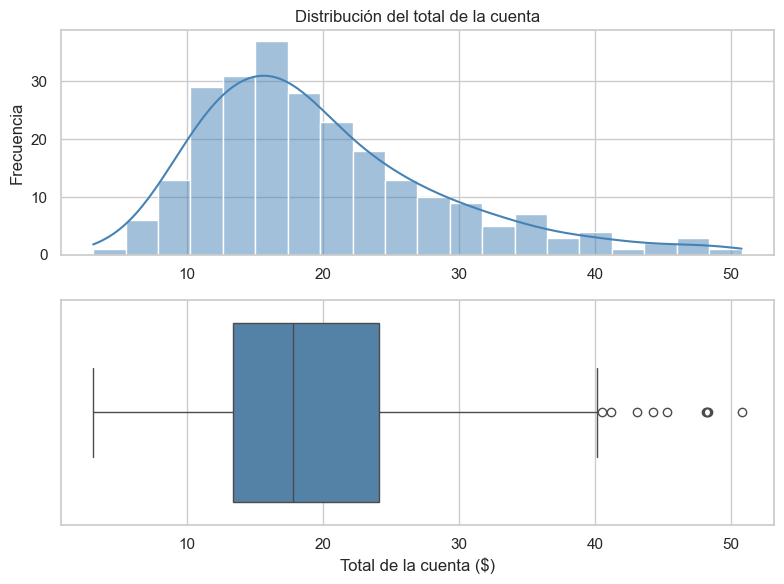

In [11]:
sns.set_theme(style="whitegrid")

# Creamos la figura
plt.figure(figsize=(8, 6))
# =========================================================
# Histograma (arriba)
# =========================================================
plt.subplot(2, 1, 1)

sns.histplot(
    data=tips,
    x="total_bill",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribución del total de la cuenta")
plt.xlabel("")
plt.ylabel("Frecuencia")


# =========================================================
# Boxplot (abajo)
# =========================================================
plt.subplot(2, 1, 2)

sns.boxplot(
    data=tips,
    x="total_bill",
    color="steelblue"
)

plt.xlabel("Total de la cuenta ($)")
plt.ylabel("")


# =========================================================
# Ajuste final
# =========================================================
plt.tight_layout()
plt.show()

**Análisis:**
- ¿La mediana del boxplot coincide con el pico del histograma?
- ¿Los outliers del boxplot corresponden a la "cola" del histograma?
- ¿Qué gráfico te da más información sobre la asimetría de la distribución?

### 5.2 Comparación entre dos variables: `total_bill` vs `tip`

Ahora aplicamos el mismo patrón para comparar la distribución de dos variables.

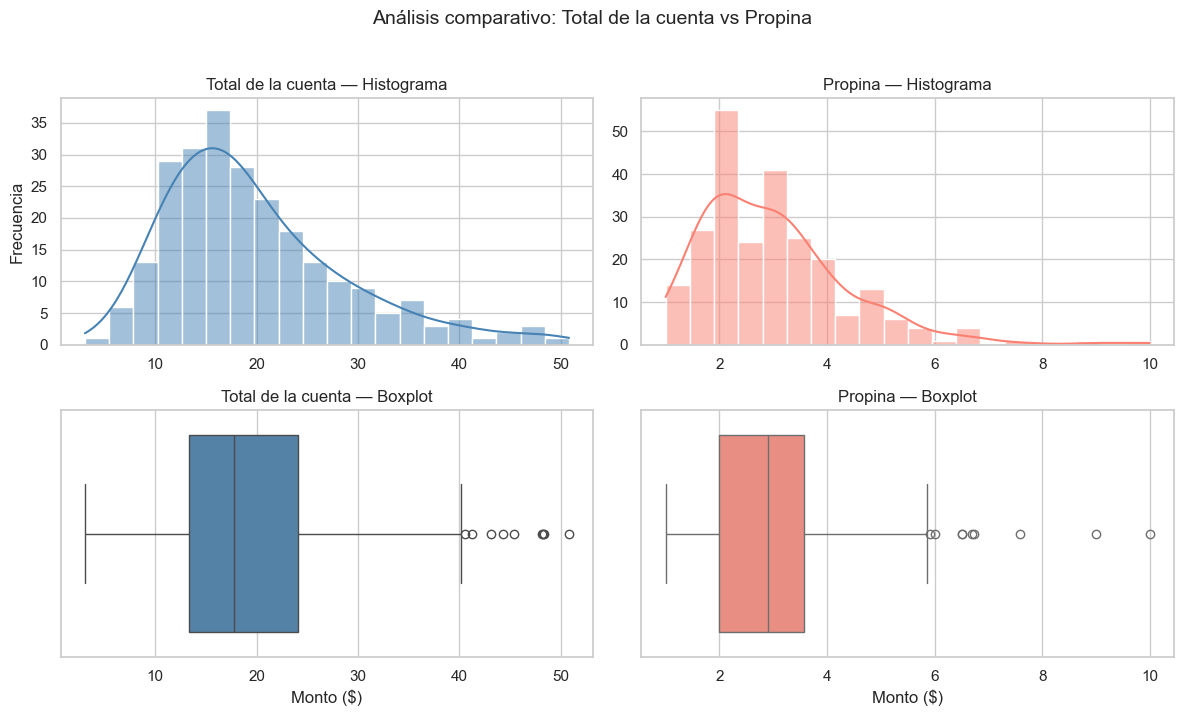

In [12]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 7))

# =========================================================
# Histograma — total_bill
# =========================================================
plt.subplot(2, 2, 1)

sns.histplot(
    data=tips,
    x="total_bill",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Total de la cuenta — Histograma")
plt.xlabel("")
plt.ylabel("Frecuencia")


# =========================================================
# Histograma — tip
# =========================================================
plt.subplot(2, 2, 2)

sns.histplot(
    data=tips,
    x="tip",
    bins=20,
    kde=True,
    color="salmon"
)

plt.title("Propina — Histograma")
plt.xlabel("")
plt.ylabel("")


# =========================================================
# Boxplot — total_bill
# =========================================================
plt.subplot(2, 2, 3)

sns.boxplot(
    data=tips,
    x="total_bill",
    color="steelblue"
)

plt.title("Total de la cuenta — Boxplot")
plt.xlabel("Monto ($)")


# =========================================================
# Boxplot — tip
# =========================================================
plt.subplot(2, 2, 4)

sns.boxplot(
    data=tips,
    x="tip",
    color="salmon"
)

plt.title("Propina — Boxplot")
plt.xlabel("Monto ($)")


# =========================================================
# Título general
# =========================================================
plt.suptitle(
    "Análisis comparativo: Total de la cuenta vs Propina",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

**Análisis comparativo:**
- ¿Cuál de las dos variables tiene mayor dispersión relativa?
- ¿Cuál tiene más outliers?
- ¿Las distribuciones tienen formas similares o distintas?
- ¿Qué medida de posición central usarías para describir cada variable y por qué?